# On-Chain Extension
Add DexScreener + GNN features to existing scam analysis.
Run this notebook **after** `scam_trend_overall_analysis.ipynb` so `df_all` already exists.
Place `onchain_fetcher.py` and `gnn_model.py` in the same folder as this notebook.

## Step 1 — Install dependencies

In [1]:
# Run once — installs all required packages
import sys

# Core graph/ML
!{sys.executable} -m pip install torch --index-url https://download.pytorch.org/whl/cpu -q
!{sys.executable} -m pip install torch_geometric -q
!{sys.executable} -m pip install networkx requests -q

print('All packages installed.')

All packages installed.


## Step 2 — Fetch DexScreener data for your 4 scams

In [2]:
from onchain_fetcher import fetch_multiple_tokens, fetch_all_scam_wallets, extract_onchain_features

# DexScreener ticker symbols for each scam in your dataset
# Note: OneCoin and Centra were not on-chain DEX tokens;
# DexScreener will return empty for them (expected)
SCAM_TOKENS = ['FTX', 'CEL', 'CENTRA', 'ONE']

df_dex = fetch_multiple_tokens(SCAM_TOKENS)
df_dex.to_csv('dexscreener_data.csv', index=False)

print(df_dex[['token', 'chain', 'volume_24h', 'liquidity_usd',
              'buy_sell_ratio', 'volume_liquidity_ratio']].to_string(index=False))

[DexScreener] Searching for 'FTX'...
  Found 5 pair(s) for 'FTX'
[DexScreener] Searching for 'CEL'...
  Found 5 pair(s) for 'CEL'
[DexScreener] Searching for 'CENTRA'...
  Found 5 pair(s) for 'CENTRA'
[DexScreener] Searching for 'ONE'...
  Found 5 pair(s) for 'ONE'

[DexScreener] Total rows fetched: 20
 token      chain  volume_24h  liquidity_usd  buy_sell_ratio  volume_liquidity_ratio
   FTX        bsc       94.04       22173.03        0.333333            4.241189e-03
   FTX     solana      380.19       18507.11        0.200000            2.054292e-02
   FTX     solana       56.96       14658.91        8.000000            3.885691e-03
   FTX   ethereum     5053.53       10843.74        0.500000            4.660320e-01
   FTX     solana     4758.84       96777.34        1.181818            4.917308e-02
   CEL   ethereum       44.89       71037.74        0.000000            6.319176e-04
   CEL   ethereum      248.06       17252.48        0.750000            1.437822e-02
   CEL pulsechai

## Step 3 — Fetch wallet transactions from Etherscan
> Get your free API key at https://etherscan.io/register  
> Then paste it in `onchain_fetcher.py` at the `ETHERSCAN_API_KEY` line.

In [3]:
from onchain_fetcher import fetch_all_scam_wallets, extract_onchain_features

# Fetch transactions for all known scam wallets
tx_df = fetch_all_scam_wallets(delay=0.25)

if not tx_df.empty:
    tx_df.to_csv('scam_transactions.csv', index=False)
    print(f'Saved {len(tx_df)} transactions → scam_transactions.csv')
    print(tx_df[['from_address', 'to_address', 'value_eth', 'label']].head())
else:
    print('No transactions fetched. Check your Etherscan API key.')


[Etherscan] Fetching scam wallet transactions...

── FTX_exchange ──
  Fetching txns for 0x2faf487a44... (FTX_exchange)
    Got 1000 transactions
  Fetching txns for 0xc098b2a3aa... (FTX_exchange)
    Got 1000 transactions

── Celsius_network ──
  Fetching txns for 0x8aceab8167... (Celsius_network)
    Got 1000 transactions
  Fetching txns for 0x1cedc0f3af... (Celsius_network)
    Got 1000 transactions

── CentraTech ──
  Fetching txns for 0xe4818f8fde... (CentraTech)
    Etherscan: No transactions found

── OneCoin ──
  Fetching txns for 0x742d35cc66... (OneCoin)
    Got 1000 transactions

[Etherscan] Total unique transactions: 4997
Saved 4997 transactions → scam_transactions.csv
                                 from_address  \
0  0x0681d8db095565fe8a346fa0277bffde9c0edbbf   
1  0x2faf487a4414fe77e2327f0bf4ae2a264a776ad2   
2  0x2faf487a4414fe77e2327f0bf4ae2a264a776ad2   
3  0x2faf487a4414fe77e2327f0bf4ae2a264a776ad2   
4  0x2faf487a4414fe77e2327f0bf4ae2a264a776ad2   

              

In [4]:
# Extract per-wallet node features
features_df = extract_onchain_features(tx_df)
features_df.to_csv('wallet_features.csv', index=False)
print(f'Wallet features shape: {features_df.shape}')
features_df.head()

Wallet features shape: (1001, 8)


,address,total_tx,total_sent_eth,total_received_eth,avg_sent_value,unique_counterparties,error_rate,is_known_scam
0,0x00dfc1ba4d220456612792bf269438c86e3ad95e,1.0,4.899748,0.0,4.899748,1.0,0.0,0
1,0x0119a6ad89def06b82c5b9e2e09f24a3eedb1d9a,1.0,2.799748,0.0,2.799748,1.0,0.0,0
2,0x01633a040da657bdd1ca1b51b20641bb46d99c7a,1.0,8.348408,0.0,8.348408,1.0,0.0,0
3,0x01796f75fbf9777b843b599880e33516d8161bec,1.0,6.999168,0.0,6.999168,1.0,0.0,0
4,0x01d2a3cf72d7218e2a98a57e6fd39f4ea8271e02,1.0,3.201698,0.0,3.201698,1.0,0.0,0


## Step 4 — Run GNN pipeline

c:\Users\User\anaconda3\lib\site-packages\torch\__config__.py:10: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 11070). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\c10\cuda\CUDAFunctions.cpp:108.)
  return torch._C._show_config()


[GNN] Building transaction graph...
  Nodes: 1,001
  Edges: 1,013
  Known scam nodes: 5

[GNN] PyG Data object:
  Feature shape : torch.Size([1001, 6])
  Labels        : 5 scam / 996 legit
  Train nodes   : 3
  Test nodes    : 2

[GNN] Training GraphSAGE for 200 epochs...
  Epoch  50 | Loss: 0.0000
  Epoch 100 | Loss: 0.0000
  Epoch 150 | Loss: 0.0000
  Epoch 200 | Loss: 0.0000
  Training complete.

[GNN] Test set evaluation:
              precision    recall  f1-score   support

       Legit       0.00      0.00      0.00         0
        Scam       1.00      1.00      1.00         2

    accuracy                           1.00         2
   macro avg       0.50      0.50      0.50         2
weighted avg       1.00      1.00      1.00         2

  ROC-AUC: nan

[GNN] Predictions saved → gnn_predictions.csv
                                   address  gnn_scam_prob  gnn_pred_label
0x79f47638d96d4d9551e05c6778a042c76258901c            1.0               1
0x782c7c0015ff2c58c9801a63eef8b6f

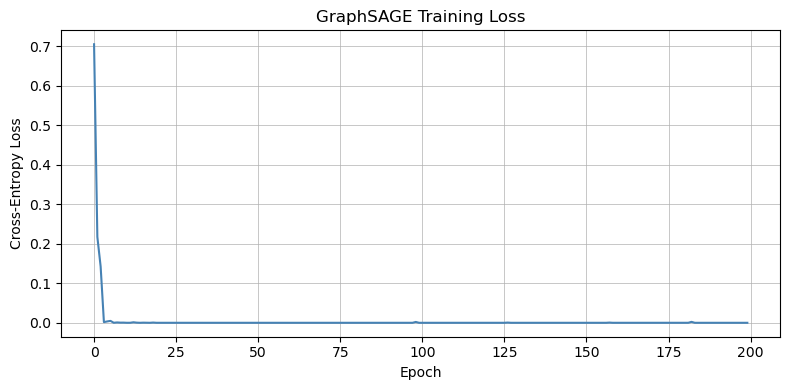

Plot saved → gnn_training_loss.png


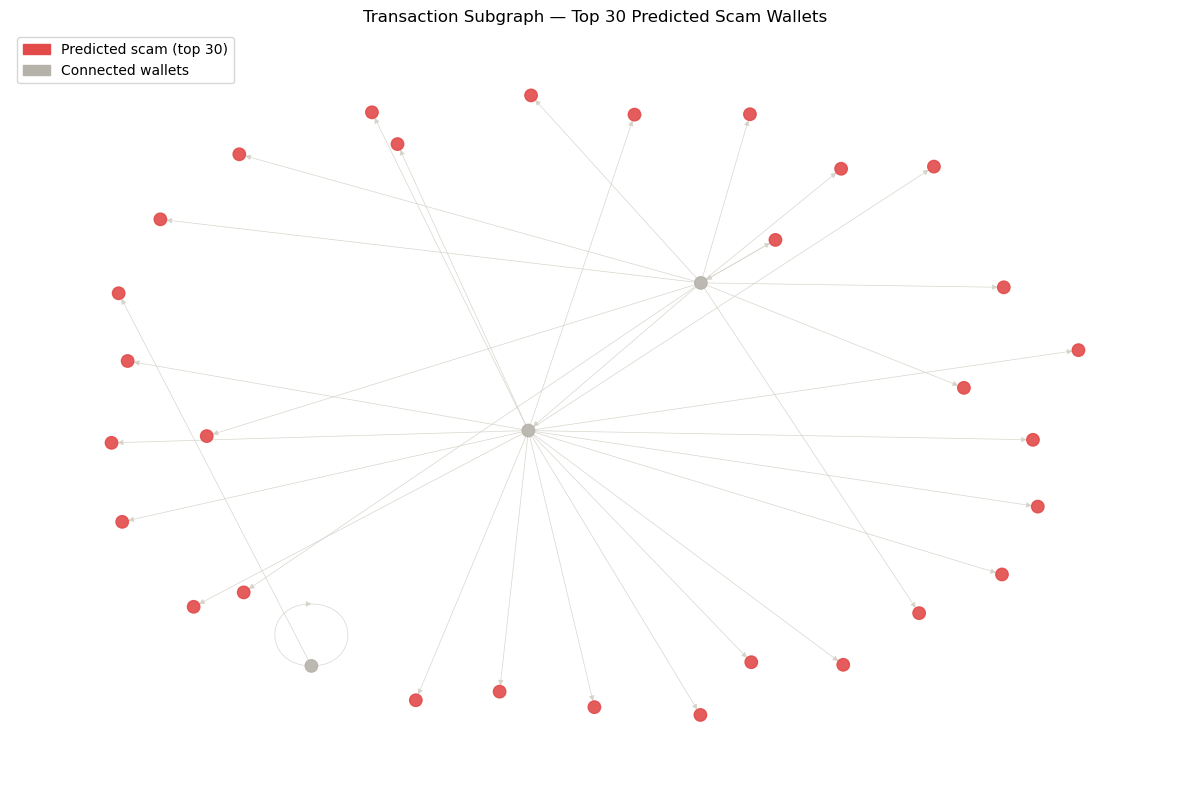

Plot saved → gnn_scam_subgraph.png


In [6]:
from gnn_model import build_graph, graph_to_pyg, train_gnn, evaluate_gnn, save_predictions
from gnn_model import plot_training_loss, visualise_scam_subgraph

# 1. Build graph
G, node_index = build_graph(tx_df, features_df)

# 2. Convert to PyTorch Geometric
data, scaler = graph_to_pyg(G, node_index)

# 3. Train GraphSAGE (200 epochs takes ~1 min on CPU)
model, train_losses = train_gnn(data, epochs=200, lr=0.005)

# 4. Evaluate
eval_results = evaluate_gnn(model, data)

# 5. Save predictions
gnn_preds = save_predictions(node_index, eval_results)

# 6. Plot
plot_training_loss(train_losses)
visualise_scam_subgraph(G, gnn_preds, top_n=30)

## Step 5 — Add on-chain features to your df_all
This merges GNN scam probabilities and DexScreener signals back into your main analysis dataframe.

In [16]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import re

In [17]:
# df_onecoin = pd.read_csv('reddit_sentiment_data_Onecoin_2024.csv')
# df_ftx = pd.read_csv('reddit_sentiment_data_FTX_2024.csv')
# df_celsius = pd.read_csv('reddit_sentiment_data_Celsius_2024.csv')
# df_centra = pd.read_csv('reddit_sentiment_data_Centra_2024.csv')

In [18]:
# df_onecoin["source"] = "OneCoin"
# df_ftx["source"] = "FTX"
# df_centra["source"] = "Centra"
# df_celsius["source"] = "Celsius"

In [19]:
# #  standardize time column
# def standardize_time(df):
#     df['timestamp_utc'] = pd.to_datetime(df['timestamp_utc'], errors='coerce')
#     df["year_month"] = df['timestamp_utc'].dt.to_period('M')
#     return df

# df_onecoin = standardize_time(df_onecoin)
# df_ftx = standardize_time(df_ftx)
# df_centra = standardize_time(df_centra)
# df_celsius = standardize_time(df_celsius)

In [20]:
# def clean_text(text):
#     text = text.lower()
#     # text = re.sub(r"http\S+", "", text)   # remove URLs
#     text = re.sub(r"[^a-z\s]", "", text)  # remove punctuation
#     text = re.sub(r"\s+", " ", text)
#     return text.strip()

In [21]:
# df_all = pd.concat([df_onecoin, df_ftx, df_centra, df_celsius], ignore_index=True)  

In [22]:
# # Step 1: count URLs on the original raw text first
# df_all['url_count'] = df_all['text'].str.count(r'https?://\S+')

# # Step 2: THEN apply cleaning as before
# df_all['cleaned_text'] = df_all['text'].fillna('').astype(str).apply(clean_text)

In [24]:
# import pandas as pd

# # ── 5a. Merge GNN wallet scores into detected wallets in df_all ──────────────
# # df_all already has 'detected_wallets' column from Cell 43 of your notebook

# gnn_preds_loaded = pd.read_csv('gnn_predictions.csv')

# # Build a lookup: address → gnn_scam_prob
# gnn_lookup = dict(zip(
#     gnn_preds_loaded['address'],
#     gnn_preds_loaded['gnn_scam_prob']
# ))

# def get_max_gnn_score(wallet_list):
#     """For a post, return the highest GNN score among its detected wallets."""
#     if not isinstance(wallet_list, list) or len(wallet_list) == 0:
#         return 0.0
#     scores = [gnn_lookup.get(w.lower(), 0.0) for w in wallet_list]
#     return max(scores) if scores else 0.0

# df_all['gnn_wallet_score'] = df_all['detected_wallets'].apply(get_max_gnn_score)

# print('GNN wallet scores added.')
# print(df_all['gnn_wallet_score'].describe())
import re
import pandas as pd

gnn_preds_loaded = pd.read_csv('gnn_predictions.csv')
gnn_lookup = dict(zip(
    gnn_preds_loaded['address'],
    gnn_preds_loaded['gnn_scam_prob']
))

# Extract Ethereum wallet addresses from post text using regex
ETH_PATTERN = re.compile(r'0x[a-fA-F0-9]{40}')

def extract_wallets_from_text(text):
    if not isinstance(text, str):
        return []
    return ETH_PATTERN.findall(text)

def get_max_gnn_score(text):
    wallets = extract_wallets_from_text(text)
    if not wallets:
        return 0.0
    scores = [gnn_lookup.get(w.lower(), 0.0) for w in wallets]
    return max(scores)

# Apply to text column
df_all['gnn_wallet_score'] = df_all['text'].apply(get_max_gnn_score)

print('GNN wallet scores added.')
print(f"Posts with wallet addresses found: {(df_all['gnn_wallet_score'] > 0).sum()}")
print(df_all['gnn_wallet_score'].describe())

GNN wallet scores added.
Posts with wallet addresses found: 8
count    195556.000000
mean          0.000041
std           0.006396
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: gnn_wallet_score, dtype: float64


In [25]:
# ── 5b. Merge DexScreener signals into df_all ────────────────────────────────
df_dex_loaded = pd.read_csv('dexscreener_data.csv')

# Map token symbol → scam source name
TOKEN_TO_SOURCE = {
    'FTX':    'FTX',
    'CEL':    'Celsius',
    'CENTRA': 'CentraTech',
    'ONE':    'OneCoin',
}

# Average DexScreener metrics per source (in case of multiple pairs)
dex_summary = (
    df_dex_loaded
    .assign(source=df_dex_loaded['token'].map(TOKEN_TO_SOURCE))
    .dropna(subset=['source'])
    .groupby('source')
    .agg(
        avg_volume_24h           = ('volume_24h',             'mean'),
        avg_liquidity_usd        = ('liquidity_usd',          'mean'),
        avg_buy_sell_ratio       = ('buy_sell_ratio',         'mean'),
        avg_volume_liq_ratio     = ('volume_liquidity_ratio', 'mean'),
        avg_price_change_24h     = ('price_change_24h',       'mean'),
    )
    .reset_index()
)

df_all = df_all.merge(dex_summary, on='source', how='left')

print('DexScreener features merged.')
print(df_all[['source', 'avg_volume_24h', 'avg_buy_sell_ratio']].drop_duplicates())

DexScreener features merged.
         source  avg_volume_24h  avg_buy_sell_ratio
0       OneCoin      255610.264            0.880686
7385        FTX        2068.712            2.043030
124509   Centra             NaN                 NaN
127455  Celsius          59.052            0.350000


## Step 6 — Re-train XGBoost with on-chain features

In [34]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt

FEATURES = [
    'text_length', 'word_count', 'url_count',
    'contains_scam_keywords', 'is_comment', 'sentiment',
    'gnn_wallet_score', 'avg_buy_sell_ratio',
    'avg_volume_liq_ratio', 'avg_price_change_24h',
]

SCAMS    = ['FTX', 'Celsius', 'OneCoin', 'Centra']
results  = {}
all_true, all_proba = [], []

# ── Leave-One-Scam-Out ────────────────────────────────────────────────────────
for test_scam in SCAMS:
    train_df = df_all[df_all['source'] != test_scam]
    test_df  = df_all[df_all['source'] == test_scam]

    X_train  = train_df[FEATURES].fillna(0)
    y_train  = train_df['pre_collapse']
    X_test   = test_df[FEATURES].fillna(0)
    y_test   = test_df['pre_collapse']

    # Skip if test set has only one class
    if y_test.nunique() < 2:
        print(f"Skipping {test_scam} — only one class in test set")
        continue

    xgb = XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric='logloss', random_state=42
    )
    xgb.fit(X_train, y_train)

    y_pred  = xgb.predict(X_test)
    y_proba = xgb.predict_proba(X_test)[:, 1]
    auc     = roc_auc_score(y_test, y_proba)

    results[test_scam] = {
        'auc':    round(auc, 4),
        'report': classification_report(y_test, y_pred,
                      target_names=['Post-collapse','Pre-collapse'],
                      zero_division=0)
    }

    all_true.extend(y_test.tolist())
    all_proba.extend(y_proba.tolist())

    print(f"\n{'='*50}")
    print(f"Test scam: {test_scam} | Train scams: {[s for s in SCAMS if s != test_scam]}")
    print(f"Test samples: {len(y_test):,} | Pre-collapse: {y_test.sum():,} | Post-collapse: {(y_test==0).sum():,}")
    print(results[test_scam]['report'])
    print(f"ROC-AUC: {results[test_scam]['auc']}")


Test scam: FTX | Train scams: ['Celsius', 'OneCoin', 'Centra']
Test samples: 117,124 | Pre-collapse: 27,186 | Post-collapse: 89,938
               precision    recall  f1-score   support

Post-collapse       0.77      0.99      0.87     89938
 Pre-collapse       0.33      0.01      0.02     27186

     accuracy                           0.77    117124
    macro avg       0.55      0.50      0.44    117124
 weighted avg       0.67      0.77      0.67    117124

ROC-AUC: 0.5276

Test scam: Celsius | Train scams: ['FTX', 'OneCoin', 'Centra']
Test samples: 68,101 | Pre-collapse: 30,751 | Post-collapse: 37,350
               precision    recall  f1-score   support

Post-collapse       0.55      1.00      0.71     37350
 Pre-collapse       0.60      0.01      0.01     30751

     accuracy                           0.55     68101
    macro avg       0.58      0.50      0.36     68101
 weighted avg       0.57      0.55      0.39     68101

ROC-AUC: 0.548

Test scam: OneCoin | Train scams: ['F

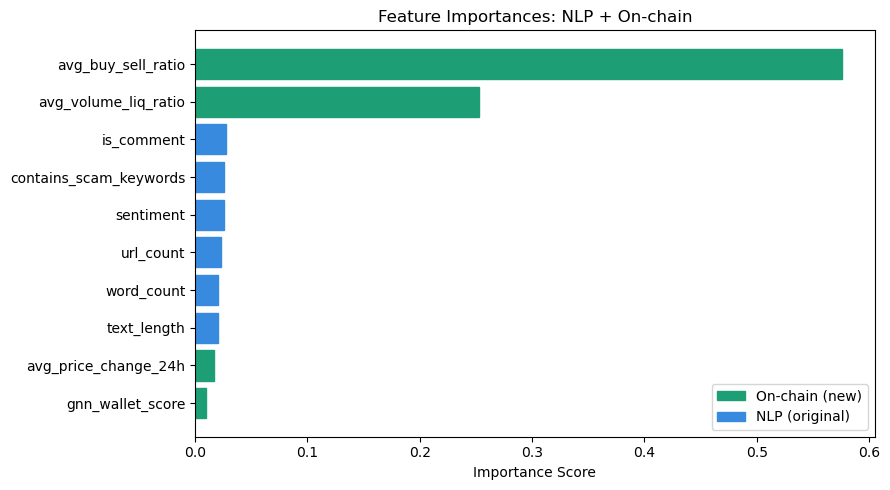

In [35]:
# ── Feature importance plot ───────────────────────────────────────────────────
importances = xgb.feature_importances_
sorted_idx  = importances.argsort()

ONCHAIN = {'gnn_wallet_score','avg_buy_sell_ratio',
           'avg_volume_liq_ratio','avg_price_change_24h'}

plt.figure(figsize=(9, 5))
bars = plt.barh([FEATURES[i] for i in sorted_idx], importances[sorted_idx])
for bar, idx in zip(bars, sorted_idx):
    bar.set_color('#1D9E75' if FEATURES[idx] in ONCHAIN else '#378ADD')

from matplotlib.patches import Patch
plt.legend(handles=[
    Patch(color='#1D9E75', label='On-chain (new)'),
    Patch(color='#378ADD', label='NLP (original)'),
])
plt.xlabel('Importance Score')
plt.title('Feature Importances: NLP + On-chain')
plt.tight_layout()
plt.savefig('xgb_feature_importance.png', dpi=150)
plt.show()

## Step 7 — ROC curve comparison: before vs after on-chain features

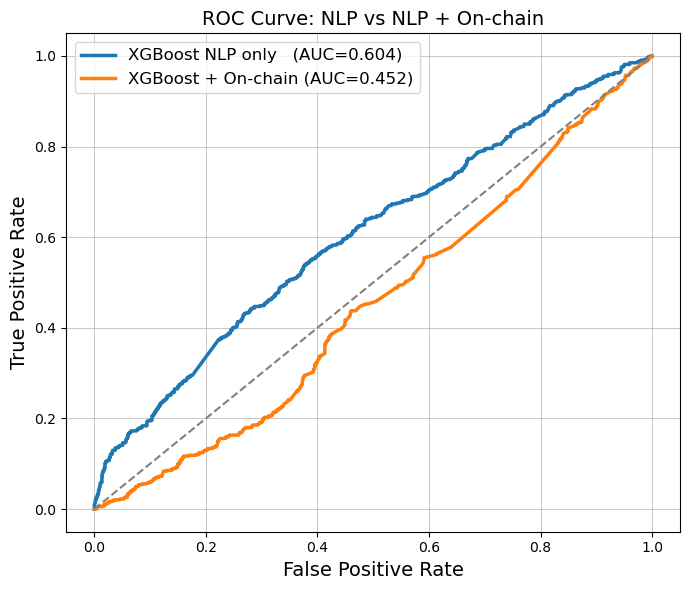

In [36]:
from sklearn.metrics import roc_curve, auc

# Original XGBoost (NLP only) — re-run on same split for fair comparison
FEATURES_ORIGINAL = [
    'text_length', 'word_count', 'url_count',
    'contains_scam_keywords', 'is_comment', 'sentiment'
]
xgb_original = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    eval_metric='logloss', random_state=42
)
xgb_original.fit(X_train[FEATURES_ORIGINAL], y_train)
probs_original = xgb_original.predict_proba(X_test[FEATURES_ORIGINAL])[:, 1]
probs_onchain  = xgb_onchain.predict_proba(X_test)[:, 1]

# Plot
plt.figure(figsize=(7, 6))

fpr1, tpr1, _ = roc_curve(y_test, probs_original)
fpr2, tpr2, _ = roc_curve(y_test, probs_onchain)

plt.plot(fpr1, tpr1, linewidth=2.5, label=f'XGBoost NLP only   (AUC={auc(fpr1,tpr1):.3f})')
plt.plot(fpr2, tpr2, linewidth=2.5, label=f'XGBoost + On-chain (AUC={auc(fpr2,tpr2):.3f})')
plt.plot([0,1], [0,1], linestyle='--', linewidth=1.5, color='gray')

plt.xlabel('False Positive Rate', fontsize=14)
plt.ylabel('True Positive Rate', fontsize=14)
plt.title('ROC Curve: NLP vs NLP + On-chain', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linewidth=0.5)
plt.tight_layout()
plt.savefig('roc_onchain_comparison.png', dpi=150)
plt.show()

## Step 8 — GNN scam score trend over time
See whether wallet-linked scam activity spikes before/after known scam events.

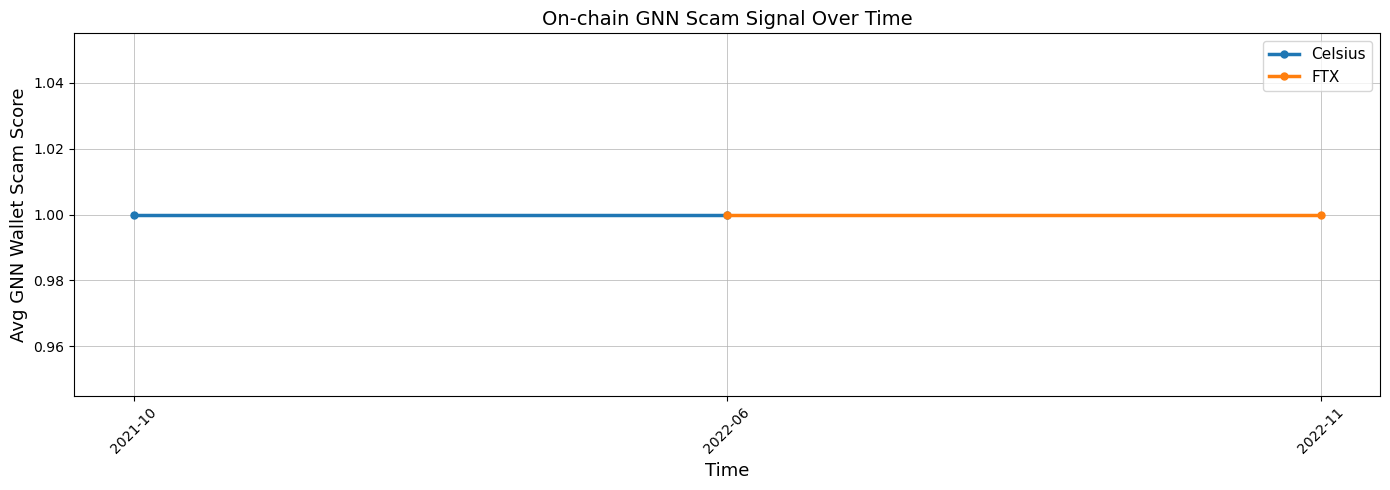

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Group by month and source — track average GNN score over time
gnn_trend = (
    df_all[df_all['gnn_wallet_score'] > 0]
    .groupby(['year_month', 'source'])['gnn_wallet_score']
    .mean()
    .reset_index()
)
gnn_trend['year_month'] = gnn_trend['year_month'].astype(str)

plt.figure(figsize=(14, 5))

for scam in gnn_trend['source'].unique():
    temp = gnn_trend[gnn_trend['source'] == scam]
    plt.plot(temp['year_month'], temp['gnn_wallet_score'],
             marker='o', linewidth=2.5, markersize=5, label=scam)

plt.xlabel('Time', fontsize=13)
plt.ylabel('Avg GNN Wallet Scam Score', fontsize=13)
plt.title('On-chain GNN Scam Signal Over Time', fontsize=14)
plt.xticks(rotation=45, fontsize=10)
plt.legend(fontsize=11)
plt.grid(True, linewidth=0.5)
plt.tight_layout()
plt.savefig('gnn_trend_over_time.png', dpi=150)
plt.show()